# Step 5 – Bayesian Hyperparameter Optimisation
**Code used:** this notebook; search space in `configs/bayes_search_space.json`.
**Model tuned:** the model selected in `02_Model_Comparison` (set `CHOSEN` below).
**Method:** Optuna with the TPE sampler (a Bayesian method).
**Objective:** mean observation-level Top-1 accuracy over 3-fold GroupKFold (grouped by trip) on the
**train** partition only. Student-test is used once at the end to compare untuned vs tuned.

In [1]:
import os, sys, time, json, warnings
sys.path.insert(0, os.path.abspath('..')); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, optuna
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingClassifier
from pathsnap.feature_engineering import FEATURES, build_training_table
from pathsnap.metrics import candidate_metrics, observation_top1, top1_per_point, route_continuity
from pathsnap.data_loading import load_trip, list_trips
SEED = 42; rng = np.random.default_rng(SEED)
OUT = os.path.abspath('../results/04_bayes_opt'); os.makedirs(OUT, exist_ok=True)
CHOSEN = 'HistGradientBoosting'
res = pd.read_csv('../results/03_models/model_comparison.csv')
CFG = json.load(open('../configs/bayes_search_space.json')); print('search configuration:', json.dumps(CFG['search_space']))
print(res[['model','cv_macro_f1','test_top1','test_log_loss','inference_time_s']].sort_values('test_top1', ascending=False).to_string(index=False))

search configuration: {"learning_rate": {"type": "float", "low": 0.01, "high": 0.3, "log": true}, "max_iter": {"type": "int", "low": 100, "high": 600, "step": 50}, "max_leaf_nodes": {"type": "int", "low": 15, "high": 127}, "min_samples_leaf": {"type": "int", "low": 10, "high": 300, "log": true}, "l2_regularization": {"type": "float", "low": 0.0, "high": 10.0}}
               model  cv_macro_f1  test_top1  test_log_loss  inference_time_s
        RandomForest     0.924871   0.873935       0.090681          0.172442
HistGradientBoosting     0.925035   0.872106       0.094183          0.123282
        DecisionTree     0.921188   0.871060       0.105498          0.011596
           MLP_64_32     0.915462   0.866931       0.101940          0.057539
  LogisticRegression     0.900357   0.861078       0.136293          0.021343
             KNN_k25     0.908822   0.861025       0.138211         23.988652
          GaussianNB     0.781847   0.835520       0.754756          0.069976


In [2]:
cands = pd.read_csv('../results/02_preprocessing/features/candidates_r50_k10.csv.gz', dtype={'trip_id': str})
tr_all = cands[(cands.partition=='train') & (cands.valid==1)]
keep = []
for tid, g in tr_all.groupby('trip_id'):
    pts = g.point_idx.unique()
    if len(pts) > CFG['max_points_per_trip']: pts = rng.choice(pts, CFG['max_points_per_trip'], replace=False)    # smaller sample keeps 25 trials affordable
    keep.append(g[g.point_idx.isin(pts)])
train = pd.concat(keep, ignore_index=True)
test = cands[(cands.partition=='student_test') & (cands.valid==1)].reset_index(drop=True)
X, y, groups = train[FEATURES].values, train.label.values, train.trip_id.values
Xt, yt = test[FEATURES].values, test.label.values
N_TEST_VALID = sum(int(build_training_table(load_trip('student_test', t))[1]['valid'].sum()) for t in list_trips('student_test'))
gkf = GroupKFold(n_splits=3)
print('tuning rows:', len(train), ' student-test valid points:', N_TEST_VALID)

tuning rows: 432937  student-test valid points: 19133


### Search space and why
| Hyperparameter | Range | Reason |
|---|---|---|
| learning_rate | 0.01 – 0.3 (log) | Step size of each boosting round; log scale because small values matter more |
| max_iter | 100 – 600 | Number of boosting rounds (trees) |
| max_leaf_nodes | 15 – 127 | Tree complexity |
| min_samples_leaf | 10 – 300 | Larger = smoother trees, less overfitting |
| l2_regularization | 0 – 10 | Penalises large leaf values |

In [3]:
def cv_score(params):
    f1s, top1s = [], []
    for tri, vai in gkf.split(X, y, groups):
        m = HistGradientBoostingClassifier(random_state=SEED, **params).fit(X[tri], y[tri])
        p = m.predict_proba(X[vai])[:, 1]
        v = train.iloc[vai].assign(score=p)
        top1s.append(observation_top1(v, v.groupby('trip_id').point_idx.nunique().sum()))
        f1s.append(candidate_metrics(y[vai], p)['macro_f1'])
    return np.mean(top1s), np.mean(f1s)

DEFAULT = CFG['untuned_defaults']
def objective(trial):
    params = {}
    for name, s in CFG['search_space'].items():      # search space read from the config file
        if s['type'] == 'float': params[name] = trial.suggest_float(name, s['low'], s['high'], log=s.get('log', False))
        else: params[name] = trial.suggest_int(name, s['low'], s['high'], step=s.get('step', 1), log=s.get('log', False))
    top1, f1 = cv_score(params)
    trial.set_user_attr('cv_macro_f1', f1)
    return top1

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study.enqueue_trial(DEFAULT)              # trial 0 = the untuned configuration
t0 = time.time(); study.optimize(objective, n_trials=CFG['n_trials']); opt_time = time.time() - t0
trials = study.trials_dataframe(); trials.to_csv(f'{OUT}/optuna_trials.csv', index=False)
print('optimisation time: %.0f s' % opt_time); print('best CV Top-1: %.4f' % study.best_value); print('best params:', study.best_params)

[I 2026-11-18 15:13:16,807] A new study created in memory with name: no-name-71d792e5-c7f4-413f-a368-31605de34858


[I 2026-11-18 15:13:20,959] Trial 0 finished with value: 0.8795778182793527 and parameters: {'learning_rate': 0.1, 'max_iter': 300, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'l2_regularization': 0.0}. Best is trial 0 with value: 0.8795778182793527.


[I 2026-11-18 15:13:46,676] Trial 1 finished with value: 0.8812885151284003 and parameters: {'learning_rate': 0.03574712922600244, 'max_iter': 600, 'max_leaf_nodes': 97, 'min_samples_leaf': 75, 'l2_regularization': 1.5601864044243652}. Best is trial 1 with value: 0.8812885151284003.


[I 2026-11-18 15:13:54,761] Trial 2 finished with value: 0.8785119682710293 and parameters: {'learning_rate': 0.01699897838270077, 'max_iter': 100, 'max_leaf_nodes': 112, 'min_samples_leaf': 76, 'l2_regularization': 7.080725777960454}. Best is trial 1 with value: 0.8812885151284003.


[I 2026-11-18 15:14:35,504] Trial 3 finished with value: 0.8812627268972246 and parameters: {'learning_rate': 0.010725209743171996, 'max_iter': 600, 'max_leaf_nodes': 109, 'min_samples_leaf': 20, 'l2_regularization': 1.8182496720710062}. Best is trial 1 with value: 0.8812885151284003.


[I 2026-11-18 15:14:49,515] Trial 4 finished with value: 0.8808088840919805 and parameters: {'learning_rate': 0.018659959624904916, 'max_iter': 250, 'max_leaf_nodes': 74, 'min_samples_leaf': 42, 'l2_regularization': 2.9122914019804194}. Best is trial 1 with value: 0.8812885151284003.


... (17 outputs left out)

[I 2026-11-18 15:17:46,555] Trial 22 finished with value: 0.8795756056091305 and parameters: {'learning_rate': 0.03807330180212356, 'max_iter': 100, 'max_leaf_nodes': 75, 'min_samples_leaf': 143, 'l2_regularization': 6.450532341690628}. Best is trial 15 with value: 0.8821958903063227.


[I 2026-11-18 15:18:05,506] Trial 23 finished with value: 0.8818060834044962 and parameters: {'learning_rate': 0.05188775394906292, 'max_iter': 300, 'max_leaf_nodes': 75, 'min_samples_leaf': 133, 'l2_regularization': 7.803336076654686}. Best is trial 15 with value: 0.8821958903063227.


[I 2026-11-18 15:18:26,589] Trial 24 finished with value: 0.8816429259122359 and parameters: {'learning_rate': 0.05675174533817085, 'max_iter': 400, 'max_leaf_nodes': 62, 'min_samples_leaf': 144, 'l2_regularization': 7.229193095271656}. Best is trial 15 with value: 0.8821958903063227.


optimisation time: 310 s
best CV Top-1: 0.8822
best params: {'learning_rate': 0.06190757560199764, 'max_iter': 250, 'max_leaf_nodes': 58, 'min_samples_leaf': 264, 'l2_regularization': 7.12822841478087}


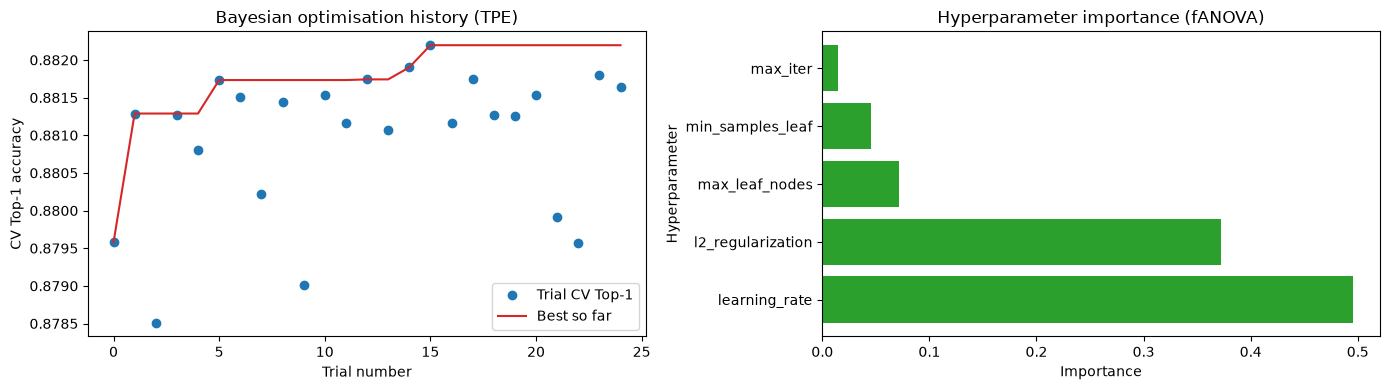

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(trials.number, trials.value, 'o', color='tab:blue', label='Trial CV Top-1')
ax[0].plot(trials.number, trials.value.cummax(), '-', color='tab:red', label='Best so far')
ax[0].set_title('Bayesian optimisation history (TPE)'); ax[0].set_xlabel('Trial number'); ax[0].set_ylabel('CV Top-1 accuracy'); ax[0].legend()
imp = optuna.importance.get_param_importances(study)
ax[1].barh(list(imp.keys()), list(imp.values()), color='tab:green')
ax[1].set_title('Hyperparameter importance (fANOVA)'); ax[1].set_xlabel('Importance'); ax[1].set_ylabel('Hyperparameter')
plt.tight_layout(); plt.savefig(f'{OUT}/optimisation_history.png'); plt.show()

### Untuned vs tuned: same data, same metrics

In [5]:
arcs_by_trip = {t: load_trip('student_test', t)['arcs'].values for t in list_trips('student_test')}
rows = {}
for name, params in [('untuned', DEFAULT), ('tuned', study.best_params)]:
    cv_top1, cv_f1 = cv_score(params)
    t0 = time.time(); m = HistGradientBoostingClassifier(random_state=SEED, **params).fit(X, y); fit_t = time.time() - t0
    t0 = time.time(); p = m.predict_proba(Xt)[:, 1]; inf_t = time.time() - t0
    cm = candidate_metrics(yt, p); te = test.assign(score=p); top = top1_per_point(te)
    cont = np.nanmean([route_continuity(g.sort_values('point_idx').arc_id.values, arcs_by_trip[t]) for t, g in top.groupby('trip_id')])
    rows[name] = dict(cv_top1=cv_top1, cv_macro_f1=cv_f1, test_top1=observation_top1(te, N_TEST_VALID),
                      test_macro_f1=cm['macro_f1'], test_log_loss=cm['log_loss'], route_continuity=cont,
                      fit_time_s=fit_t, inference_time_s=inf_t)
    if name == 'tuned':
        os.makedirs('../models', exist_ok=True); joblib.dump(m, '../models/final_model.joblib')
        json.dump(study.best_params, open('../models/final_model_params.json', 'w'), indent=2)
cmp = pd.DataFrame(rows).T; cmp.to_csv(f'{OUT}/untuned_vs_tuned.csv'); cmp.round(4)

,cv_top1,cv_macro_f1,test_top1,test_macro_f1,test_log_loss,route_continuity,fit_time_s,inference_time_s
untuned,0.8796,0.9267,0.8732,0.9231,0.0907,0.9318,2.1833,0.1279
tuned,0.8822,0.9274,0.8712,0.9235,0.0897,0.9347,5.8949,0.3936


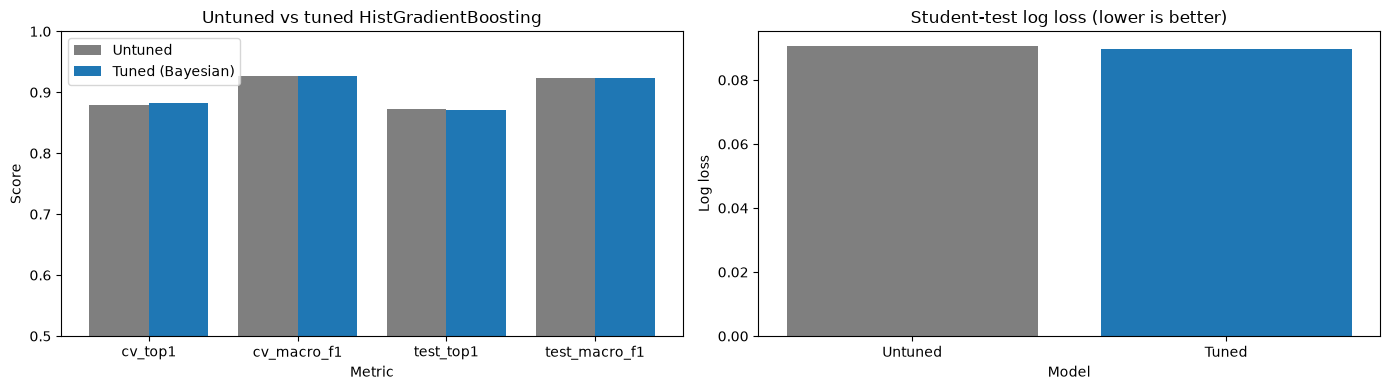

In [6]:
cols = ['cv_top1','cv_macro_f1','test_top1','test_macro_f1']
fig, ax = plt.subplots(1, 2, figsize=(14, 4)); x = np.arange(len(cols))
ax[0].bar(x-0.2, cmp.loc['untuned', cols], 0.4, label='Untuned', color='tab:gray')
ax[0].bar(x+0.2, cmp.loc['tuned', cols], 0.4, label='Tuned (Bayesian)', color='tab:blue')
ax[0].set_xticks(x); ax[0].set_xticklabels(cols); ax[0].set_ylim(0.5, 1.0)
ax[0].set_title('Untuned vs tuned HistGradientBoosting'); ax[0].set_xlabel('Metric'); ax[0].set_ylabel('Score'); ax[0].legend()
ax[1].bar(['Untuned','Tuned'], cmp.test_log_loss, color=['tab:gray','tab:blue'])
ax[1].set_title('Student-test log loss (lower is better)'); ax[1].set_xlabel('Model'); ax[1].set_ylabel('Log loss')
plt.tight_layout(); plt.savefig(f'{OUT}/untuned_vs_tuned.png'); plt.show()